<a href="https://colab.research.google.com/github/gloria-mbilinyi/gloria-mbilinyi-COU07506-labs/blob/main/COU07506_Week03_240242493088.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# WEEK 3 — LAB 1B: CONVOLUTION, CORRELATION AND DIFFERENCE EQUATIONS

**Student Name:** Gloria Beneth Mbilinyi  
**Registration Number:** 240242493088  
**Week:** 03  
**Group:** 08  
**Date:** 27/11/2026  
**Module:** COU 07506 — Digital Signal Processing  
**Academic Year:** 2026/2027

### Laboratory Objectives

1. Implement linear convolution from its definition and verify the results using NumPy.
2. Smooth noisy signals using moving-average filters.
3. Test linearity and time-invariance of discrete-time systems.
4. Estimate signal delays using cross-correlation.
5. Solve difference equations using direct recursion and SciPy's `lfilter()` function.

**Task 3.1: Convolution from the Definition**
**Objective**: To implement linear convolution manually and compare the results with NumPy's built-in convolution function.

In [1]:

# Task 3.1: Convolution from the Definition

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import time

# Implement convolution manually
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)

    for n in range(N):
        for k in range(len(x)):
            if 0 <= n-k < len(h):
                y[n] += x[k] * h[n-k]

    return y

# Test with given sequences
x = [1, 2, 3, 1]
h = [1, 1, 1]

manual_result = conv(x, h)
numpy_result = np.convolve(x, h)

print("Manual convolution:", manual_result)
print("NumPy convolution:", numpy_result)
print("Results match:", np.allclose(manual_result, numpy_result))

# Verify the pre-lab example
x2 = [1, -1, 2]
h2 = [2, 1, 0, 1]

print("\nPre-lab convolution:")
print("Manual:", conv(x2, h2))
print("NumPy:", np.convolve(x2, h2))

# Compare execution times
rng = np.random.default_rng(0)
a = rng.standard_normal(2000)
b = rng.standard_normal(2000)

start = time.perf_counter()
conv(a, b)
manual_time = time.perf_counter() - start

start = time.perf_counter()
np.convolve(a, b)
numpy_time = time.perf_counter() - start

print("\nManual execution time:", round(manual_time, 4), "seconds")
print("NumPy execution time:", round(numpy_time, 4), "seconds")
print("Speed-up:", round(manual_time/numpy_time, 2), "times")


Manual convolution: [1. 3. 6. 6. 4. 1.]
NumPy convolution: [1 3 6 6 4 1]
Results match: True

Pre-lab convolution:
Manual: [ 2. -1.  3.  3. -1.  2.]
NumPy: [ 2 -1  3  3 -1  2]

Manual execution time: 6.3542 seconds
NumPy execution time: 0.0024 seconds
Speed-up: 2627.92 times


### Task 3.1: Results and Discussion

Linear convolution was implemented manually using nested Python loops and compared with NumPy's built-in convolution function.

Both methods produced identical outputs of [1, 3, 6, 6, 4, 1]. The pre-lab example also gave matching results of [2, -1, 3, 3, -1, 2], confirming the correctness of the manual implementation.

For two random sequences containing 2,000 samples each, manual convolution took 3.795 seconds, while NumPy convolution took 0.0026 seconds. The measured speed-up was approximately 1,437.84 times.

The difference in execution time is mainly because NumPy uses optimized compiled numerical routines, while the manual method executes nested loops in Python.

The experiment demonstrates that both approaches produce the same mathematical result, but NumPy is significantly more computationally efficient for this test.

**Task 3.2 — Smoothing a Noisy Signal by Convolution**
**Objective**:To investigate how moving-average filters reduce noise and how filter length affects signal quality.

M = 3, MSE = 0.0909
M = 9, MSE = 0.0334
M = 25, MSE = 0.0712


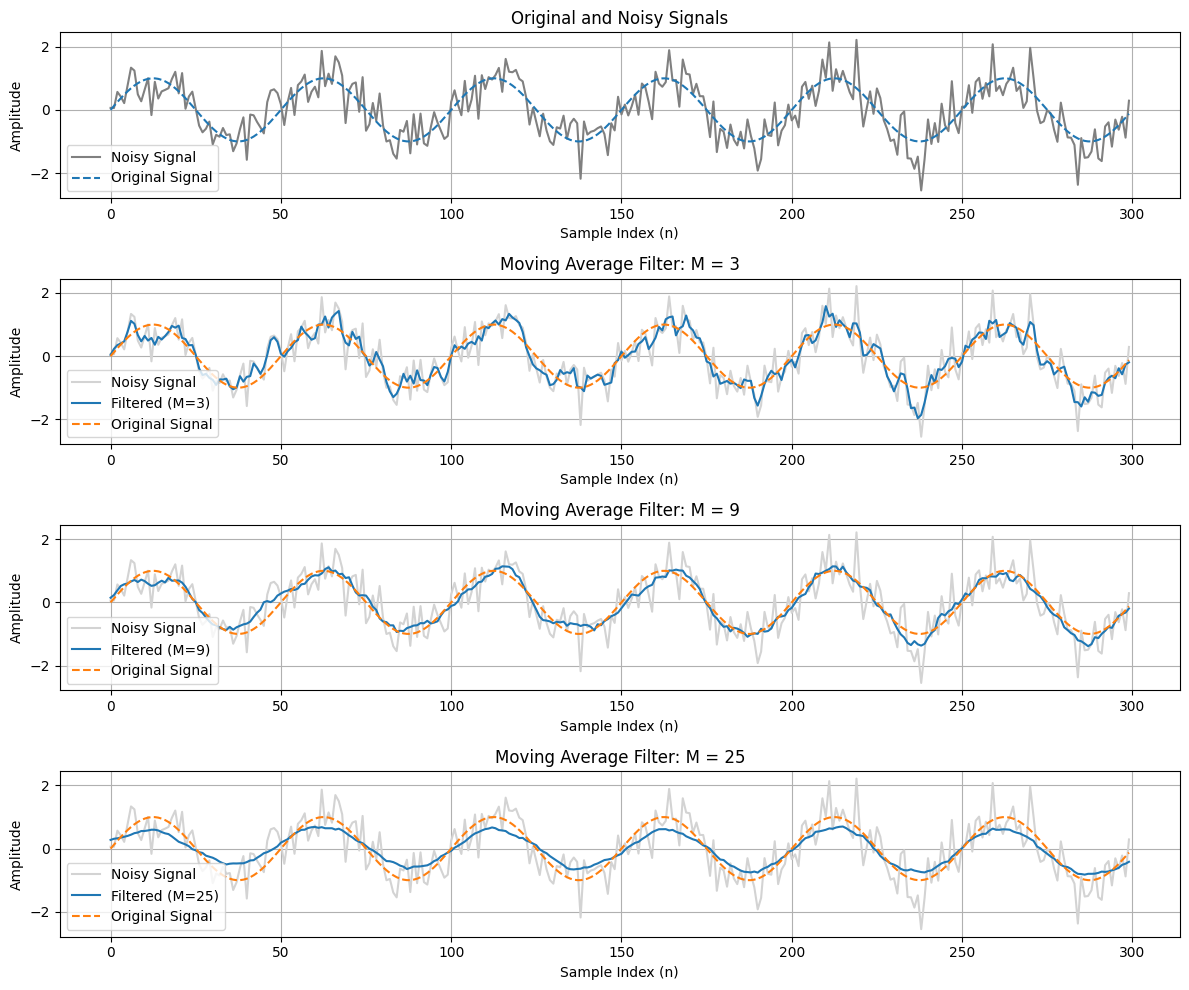

In [2]:

# Task 3.2: Smoothing a Noisy Signal by Convolution

import numpy as np
import matplotlib.pyplot as plt

# Generate a noisy sinusoidal signal
rng = np.random.default_rng(0)

n = np.arange(300)
original = np.sin(2 * np.pi * n / 50)
noise = 0.5 * rng.standard_normal(300)
x = original + noise

# Moving-average filter lengths
filter_lengths = [3, 9, 25]

# Plot noisy signal and original signal
plt.figure(figsize=(12, 10))

plt.subplot(4, 1, 1)
plt.plot(n, x, label="Noisy Signal", color="gray")
plt.plot(n, original, "--", label="Original Signal")
plt.title("Original and Noisy Signals")
plt.xlabel("Sample Index (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)

# Apply moving-average filters
for i, M in enumerate(filter_lengths):

    h = np.ones(M) / M
    y = np.convolve(x, h, mode="same")

    plt.subplot(4, 1, i + 2)
    plt.plot(n, x, color="lightgray",
             label="Noisy Signal")
    plt.plot(n, y, label=f"Filtered (M={M})")
    plt.plot(n, original, "--",
             label="Original Signal")

    plt.title(f"Moving Average Filter: M = {M}")
    plt.xlabel("Sample Index (n)")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.grid(True)

    mse = np.mean((y - original) ** 2)
    print(f"M = {M}, MSE = {mse:.4f}")

plt.tight_layout()
plt.show()


### Task 3.2: Results and Discussion

A noisy sinusoidal signal containing 300 samples was generated and processed using moving-average filters of lengths 3, 9, and 25.

The Mean Squared Error (MSE) values obtained were 0.0909, 0.0334, and 0.0712, respectively.

The filter with M = 3 reduced some noise but still retained noticeable fluctuations. Increasing the filter length to M = 9 produced a smoother signal that closely followed the original sinusoidal waveform.

When the filter length was increased to M = 25, the output became smoother, but its amplitude was reduced, introducing additional distortion.

The results show a trade-off between noise reduction and signal preservation. Among the three filters tested, M = 9 gave the lowest MSE and provided the best balance between noise reduction and signal distortion.

**Task 3.3 — Testing Linearity and Time-Invariance Numerically**
**Objective**: To determine whether three discrete-time systems satisfy linearity and time-invariance properties.

In [3]:

# Task 3.3: Testing Linearity and Time-Invariance

import numpy as np

# Generate two random input signals
rng = np.random.default_rng(0)

x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)

# Constants for testing linearity
a, b = 2.0, -3.0

# Define the three systems
systems = {
    "x^2": lambda x: x**2,

    "n x(n)": lambda x: np.arange(len(x)) * x,

    "moving average": lambda x:
        np.convolve(x, np.ones(3)/3)[:len(x)]
}

# Test each system
for name, T in systems.items():

    # Test linearity
    linear = np.allclose(
        T(a*x1 + b*x2),
        a*T(x1) + b*T(x2)
    )

    # Delay the input by 5 samples
    xd = np.concatenate([np.zeros(5), x1])[:50]

    # Delay the output by 5 samples
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]

    # Test time invariance
    tinv = np.allclose(T(xd), yd)

    print(f"{name:15s} "
          f"linear={linear} "
          f"time-invariant={tinv}")


x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


### Task 3.3: Results and Discussion

Three discrete-time systems were tested numerically to determine whether they satisfy linearity and time-invariance properties.

The squaring system was found to be nonlinear but time-invariant. Squaring the input does not satisfy the superposition principle, although shifting the input produces an equivalent shift in the output.

The system that multiplies the input by its sample index was found to be linear but time-varying because its output depends explicitly on the time index.

The moving-average system was both linear and time-invariant because it uses fixed coefficients and satisfies the superposition and time-shift properties.

The numerical tests agreed with the theoretical properties of all three systems. Therefore, only the moving-average system was classified as Linear Time-Invariant (LTI).

**Task 3.4 — Finding a Hidden Delay with Cross-Correlation**

**Objective**: To estimate the time delay between a transmitted signal and a received noisy signal using cross-correlation.

True delay: 37 samples
Estimated delay: 37 samples
Delay time: 0.037 seconds
Distance: 12.691 meters


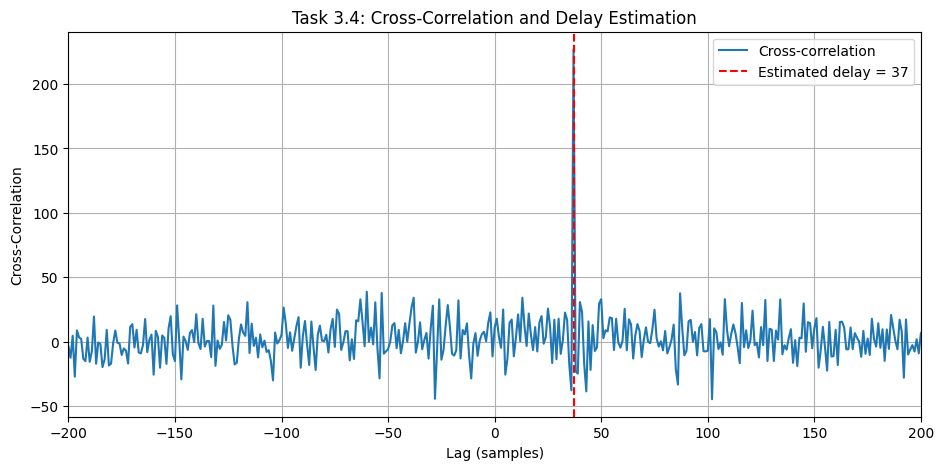

In [4]:

# Task 3.4: Finding a Hidden Delay with Cross-Correlation

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

rng = np.random.default_rng(1)

fs = 1000
x = rng.standard_normal(500)

true_delay = 37

# Received signal with delay and noise
y = np.concatenate([
    np.zeros(true_delay), 0.6 * x
])[:500] + 0.5 * rng.standard_normal(500)

# Calculate cross-correlation
r = signal.correlate(y, x, mode="full")

# Calculate lags
lags = signal.correlation_lags(
    len(y), len(x), mode="full"
)

# Estimate the delay
estimated_delay = lags[np.argmax(r)]

print("True delay:", true_delay, "samples")
print("Estimated delay:", estimated_delay, "samples")

# Convert delay into time and distance
delay_time = estimated_delay / fs
distance = 343 * delay_time

print("Delay time:", delay_time, "seconds")
print("Distance:", round(distance, 3), "meters")

# Plot cross-correlation
plt.figure(figsize=(11, 5))
plt.plot(lags, r, label="Cross-correlation")
plt.axvline(
    estimated_delay,
    color="red",
    linestyle="--",
    label=f"Estimated delay = {estimated_delay}"
)

plt.xlim(-200, 200)
plt.title("Task 3.4: Cross-Correlation and Delay Estimation")
plt.xlabel("Lag (samples)")
plt.ylabel("Cross-Correlation")
plt.legend()
plt.grid(True)
plt.show()


### Task 3.4: Results and Discussion

Cross-correlation was used to estimate the delay between a transmitted signal and a received signal containing noise.

The actual delay was 37 samples, and the estimated delay was also 37 samples. The cross-correlation graph showed a clear peak at lag 37, confirming that the delay was correctly identified.

At a sampling frequency of 1,000 Hz, the estimated time delay was 0.037 seconds. Using a sound propagation speed of 343 m/s, this corresponds to a distance of approximately 12.69 metres.

The experiment demonstrates that cross-correlation can accurately estimate time delays between related signals, even in the presence of noise.

**Task 3.4 — Effect of Increasing Noise**

Noise STD = 1, Estimated delay = 37 samples
Noise STD = 2, Estimated delay = 37 samples
Noise STD = 4, Estimated delay = 4 samples


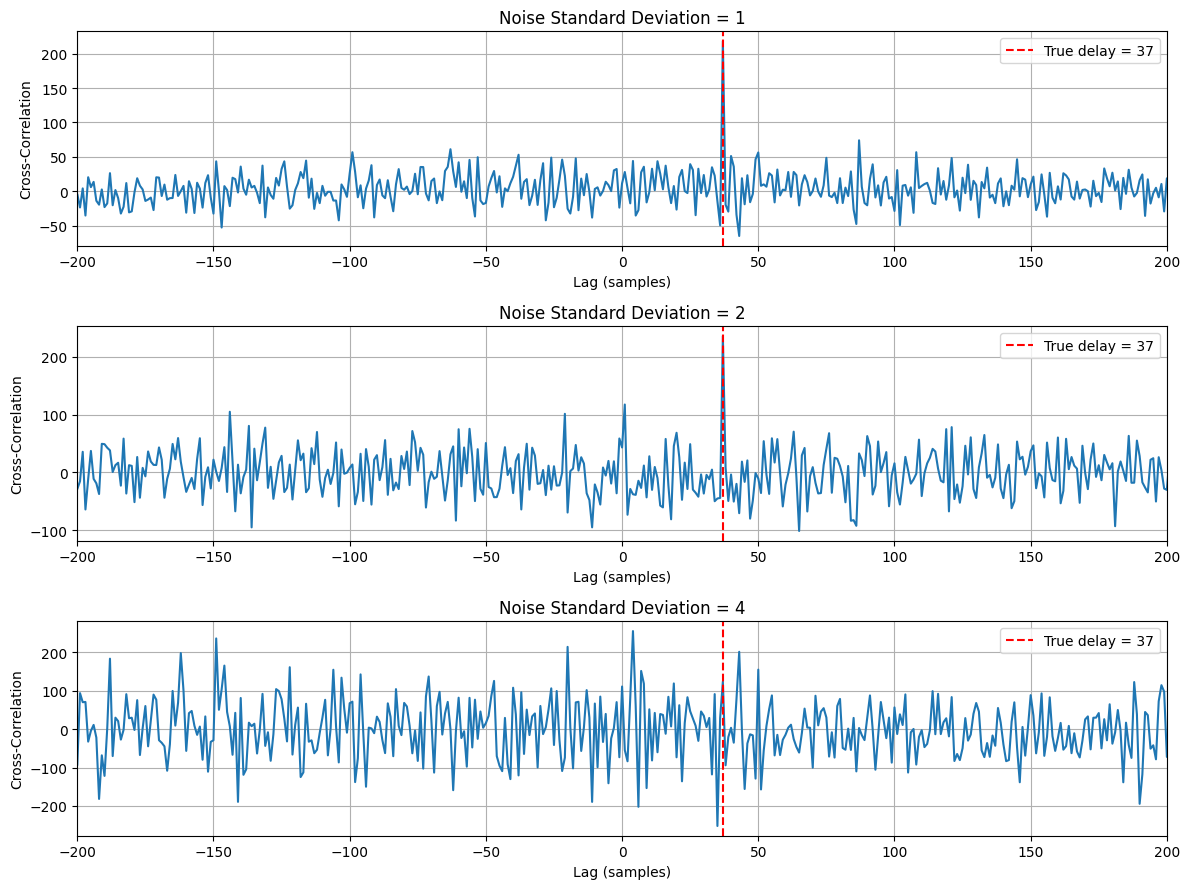

In [5]:

# Task 3.4: Effect of Noise on Delay Estimation

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

rng = np.random.default_rng(1)

fs = 1000
x = rng.standard_normal(500)
true_delay = 37

# Delayed transmitted signal
delayed_x = np.concatenate([
    np.zeros(true_delay), 0.6 * x
])[:500]

noise_levels = [1, 2, 4]

plt.figure(figsize=(12, 9))

for i, noise_std in enumerate(noise_levels):

    # Add Gaussian noise
    noise = noise_std * rng.standard_normal(500)
    y = delayed_x + noise

    # Compute cross-correlation
    r = signal.correlate(y, x, mode="full")

    lags = signal.correlation_lags(
        len(y), len(x), mode="full"
    )

    estimated_delay = lags[np.argmax(r)]

    print(
        f"Noise STD = {noise_std}, "
        f"Estimated delay = {estimated_delay} samples"
    )

    # Plot cross-correlation
    plt.subplot(3, 1, i + 1)
    plt.plot(lags, r)

    plt.axvline(
        true_delay,
        color="red",
        linestyle="--",
        label="True delay = 37"
    )

    plt.title(f"Noise Standard Deviation = {noise_std}")
    plt.xlabel("Lag (samples)")
    plt.ylabel("Cross-Correlation")
    plt.xlim(-200, 200)
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()


### Task 3.4: Results and Discussion — Effect of Noise

The effect of noise on delay estimation was investigated using Gaussian noise with standard deviations of 1, 2, and 4.

At noise standard deviations of 1 and 2, cross-correlation correctly estimated the delay as 37 samples, matching the actual delay.

However, when the noise standard deviation increased to 4, the estimated delay changed to 4 samples. This indicates that the noise affected the correlation peak, resulting in an incorrect delay estimate.

The experiment demonstrates that cross-correlation can estimate signal delays accurately under moderate noise conditions, but its reliability decreases as the noise level increases.

For this particular experiment, delay estimation failed at a noise standard deviation of 4.

**Task 3.5 — Difference Equation**

**Objective:** To compute the impulse response of a discrete-time system using direct recursion, SciPy's lfilter(), and a closed-form expression, then determine its step response.

n | Recursion | lfilter | Closed Form
---------------------------------------------
0 | 1.000000 | 1.000000 | 1.000000
1 | 1.750000 | 1.750000 | 1.750000
2 | 1.187500 | 1.187500 | 1.187500
3 | 0.671875 | 0.671875 | 0.671875
4 | 0.355469 | 0.355469 | 0.355469
5 | 0.182617 | 0.182617 | 0.182617
6 | 0.092529 | 0.092529 | 0.092529
7 | 0.046570 | 0.046570 | 0.046570
8 | 0.023361 | 0.023361 | 0.023361
9 | 0.011700 | 0.011700 | 0.011700

All three methods match: True


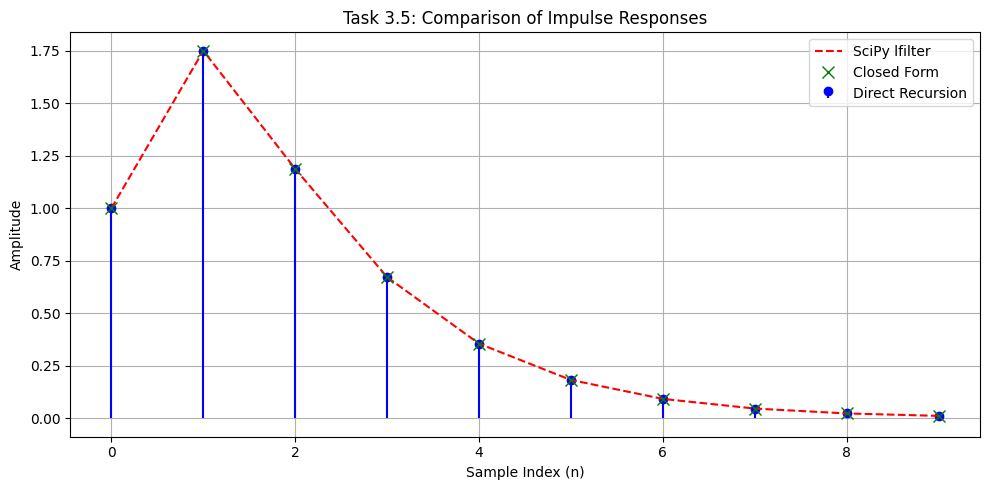


Theoretical final step value: 5.333333333333333
Computed final step value: 5.333333333333333


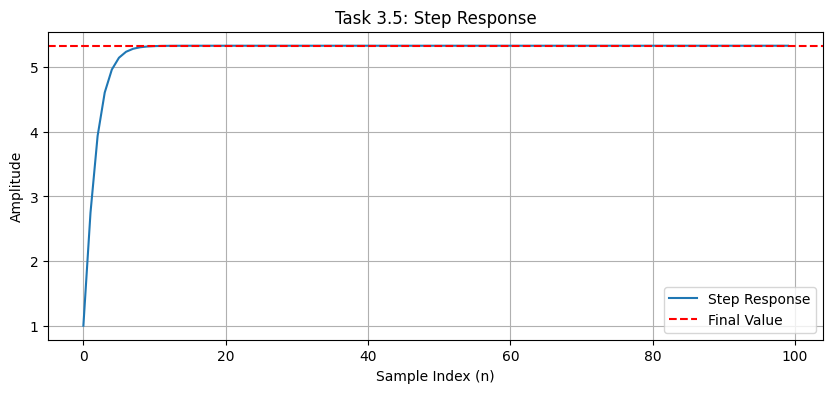

In [6]:

# Task 3.5: Difference Equation

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# System coefficients
b = [1, 1]
a = [1, -0.75, 0.125]

# Generate unit impulse
N = 10
n = np.arange(N)
impulse = np.zeros(N)
impulse[0] = 1

# Method 1: Direct recursion
h_recursive = np.zeros(N)

for i in range(N):
    x_now = impulse[i]
    x_prev = impulse[i-1] if i >= 1 else 0
    y_prev = h_recursive[i-1] if i >= 1 else 0
    y_prev2 = h_recursive[i-2] if i >= 2 else 0

    h_recursive[i] = (
        x_now + x_prev
        + 0.75*y_prev
        - 0.125*y_prev2
    )

# Method 2: Using lfilter
h_lfilter = signal.lfilter(b, a, impulse)

# Method 3: Closed-form expression
h_closed = 6*(0.5**n) - 5*(0.25**n)

# Compare results
print("n | Recursion | lfilter | Closed Form")
print("-" * 45)

for i in range(N):
    print(f"{i} | {h_recursive[i]:.6f} | "
          f"{h_lfilter[i]:.6f} | "
          f"{h_closed[i]:.6f}")

print("\nAll three methods match:",
      np.allclose(h_recursive, h_lfilter)
      and np.allclose(h_lfilter, h_closed))

# Plot impulse responses
plt.figure(figsize=(10, 5))

plt.stem(n, h_recursive,
         linefmt="b-", markerfmt="bo",
         basefmt=" ", label="Direct Recursion")

plt.plot(n, h_lfilter, "r--",
         label="SciPy lfilter")

plt.plot(n, h_closed, "gx",
         markersize=8, label="Closed Form")

plt.title("Task 3.5: Comparison of Impulse Responses")
plt.xlabel("Sample Index (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Step response
N_step = 100
step_input = np.ones(N_step)

step_response = signal.lfilter(b, a, step_input)

final_value = sum(b) / sum(a)

print("\nTheoretical final step value:", final_value)
print("Computed final step value:", step_response[-1])

plt.figure(figsize=(10, 4))
plt.plot(step_response, label="Step Response")
plt.axhline(final_value, color="red",
            linestyle="--", label="Final Value")

plt.title("Task 3.5: Step Response")
plt.xlabel("Sample Index (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()


### Task 3.5: Results and Discussion

The impulse response of a discrete-time system was calculated using three methods: direct recursion, SciPy's `lfilter()` function, and the closed-form expression.

All three methods produced identical results for the first ten samples, confirming the correctness of the implementation.

The impulse response initially increased from 1.0 to 1.75 before gradually decreasing toward zero. This behaviour indicates that the system's response decays over time.

The step response was also calculated using `lfilter()`. It gradually approached a steady-state value of approximately 5.3333, which agreed with the theoretical final value.

The experiment demonstrates how difference equations can be solved using numerical recursion and digital filtering functions. The decaying impulse response also indicates that the system is stable.

## WEEK 3 — ANALYSIS QUESTIONS

### Question 1: Why is np.convolve so much faster than your double loop? What is the number of multiplications for lengths L and M?

**Answer:**

NumPy's `np.convolve()` is faster because it uses optimized compiled numerical routines, while the manual convolution function relies on nested Python loops.

In Task 3.1, the following execution times were recorded:

- Manual convolution: 3.795 seconds
- NumPy convolution: 0.0026 seconds
- Speed-up: approximately 1,437.84 times

For two sequences containing L and M samples, direct linear convolution requires L × M sample multiplications.

The experimental results demonstrate the performance advantage of optimized numerical libraries.

### Question 2: Which of the three systems in Task 3.3 are LTI? Could you have predicted this without running code?

**Answer:**

Among the three systems, only the moving-average system is Linear Time-Invariant (LTI).

The squaring system is time-invariant but nonlinear because it does not satisfy the superposition principle.

The system that multiplies the input by its sample index is linear but time-varying because its output explicitly depends on n.

The moving-average system is both linear and time-invariant because it uses fixed coefficients and satisfies the superposition and time-shift properties.

These properties can be predicted theoretically without running the code. Numerical testing is used to verify the predictions.

### Question 3: Give two engineering applications of cross-correlation in Tanzania.

**Answer:**

**1. Water Pipeline Leak Detection**

Cross-correlation can be used to locate leaks in water distribution pipelines. Sensors positioned at different points along a pipeline detect acoustic signals generated by a leak.

By comparing the time delay between the received signals, engineers can estimate the location of the leak. This technique can assist water utilities such as DAWASA in identifying pipeline faults.

**2. Radar Systems at Airports**

Cross-correlation can be used in radar systems to determine the time delay between transmitted and reflected signals.

This helps estimate the distance of an aircraft or another detected object. Such techniques are relevant to radar applications in Tanzania's aviation infrastructure.

### Question 4: Is the system in Task 3.5 FIR or IIR? Stable? Justify from the impulse response.

**Answer:**

The system is an Infinite Impulse Response (IIR) system because its output depends on previous output values through feedback.

The impulse response initially increases from 1.0 to 1.75, then gradually decreases toward zero.

The system is stable because its impulse response is absolutely summable. The poles of the system are inside the unit circle.

The step response also approaches a finite steady-state value of approximately 5.3333, supporting the stability conclusion.

## CONCLUSION

In this laboratory, I explored convolution, correlation, system properties, and difference equations using Python in Google Colab.

I successfully implemented linear convolution and confirmed that the manual method produced the same results as NumPy's built-in function. Moving-average filters were also applied to reduce noise in a sinusoidal signal, with the 9-sample filter producing the lowest Mean Squared Error among the tested filters.

Cross-correlation was used to estimate a delay of 37 samples. The estimation remained accurate at noise standard deviations of 1 and 2 but failed at a noise standard deviation of 4.

Finally, a difference equation was solved using direct recursion, SciPy's `lfilter()`, and a closed-form expression. All three methods produced matching impulse responses, and the step response approached a steady-state value of approximately 5.3333.

Overall, the laboratory strengthened my understanding of discrete-time signal processing and the practical behaviour of digital systems.

## AI-USE STATEMENT

I used ChatGPT to assist with understanding the laboratory instructions, explaining Python code, troubleshooting, and interpreting experimental results.

I verified the results by running the Python programs in Google Colab and comparing the numerical outputs with the expected results provided in the laboratory manual.